# Continuous XNOR — data and mathematical checks

Run top to bottom. This notebook generates and visualizes the continuous data, then checks the two label rules, the conflict construction, and inverse initialization. It does not train a model.

The independent experiment uses $X=[TA_s,αUA_1,αUTA_2]$, where each positive magnitude is independently sampled from Uniform(0.5, 1.5). Labels and signs are sampled independently before the features are constructed. No normalization is applied.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, clear_output, Code

# Launch Jupyter here, or open these notebooks from the project root.
HERE = Path.cwd()
if not (HERE / 'notebook_experiment.py').exists():
    HERE = HERE / 'continuous_xnor'
assert (HERE / 'notebook_experiment.py').exists(), 'Launch Jupyter from the continuous_xnor folder.'
sys.path.insert(0, str(HERE))
from notebook_experiment import *
torch.set_num_threads(1)
RESULTS = HERE / 'results'
print('PyTorch:', torch.__version__)


PyTorch: 2.14.1+cpu


## Generate independent splits

The four split seeds are fixed in `make_splits`. Generating them again in another notebook produces the same coordinates. Across scales, we copy these coordinates and scale only the complex columns.

In [2]:
display(Code(inspect.getsource(make_data), language='python'))
splits = make_splits()
x, y = splits['train']
table = pd.DataFrame(x.numpy(), columns=['simple', 'complex_1', 'complex_2'])
table['label'] = y.numpy().ravel().astype(int)
display(table.head(10))
print('Training samples:', len(x), '| distinct coordinates:', len(torch.unique(x, dim=0)))
assert len(torch.unique(x, dim=0)) > 4
assert torch.equal((x[:, :1] > 0).float(), y)
assert torch.equal((x[:, 1:2] * x[:, 2:3] > 0).float(), y)
for alpha in [0.1, 0.5, 1, 2, 5, 10]:
    xa, ya = scale_data((x, y), alpha)
    assert torch.equal((xa[:, 1:2] * xa[:, 2:3] > 0).float(), ya)
print('Both rules recover every training label at every tested scale.')


def make_data(n, seed):
    """Generate unscaled continuous inputs whose two rules agree."""
    rng = np.random.default_rng(seed)
    y = rng.integers(0, 2, n)
    t = 2 * y - 1
    u = rng.choice([-1, 1], n)
    # Independent positive magnitudes preserve the sign-based label rules.
    magnitudes = rng.uniform(0.5, 1.5, size=(n, 3))
    x = np.column_stack([t, u, u * t]) * magnitudes
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

,simple,complex_1,complex_2,label
0,-1.061043,0.882568,-1.461499,0
1,-0.672525,-0.545493,1.408351,0
2,0.765850,-0.651519,-0.885284,1
3,-0.842892,0.854662,-1.351114,0
4,0.790429,-0.632648,-0.715684,1
5,1.449695,0.928842,0.860716,1
6,1.277367,-1.435598,-1.010208,1
7,-1.314566,0.764575,-0.850444,0
8,-1.076439,0.736397,-0.775215,0
9,-0.687544,0.762314,-1.339324,0


Training samples: 1024 | distinct coordinates: 1024
Both rules recover every training label at every tested scale.


## See the difference from four prototypes

The simple coordinate has positive or negative continuously varying magnitude. The complex coordinates fill four rectangular regions, with equal-sign quadrants belonging to class 1. Points near either axis are excluded by the positive magnitude range. These are continuous regions, not four repeated corners.

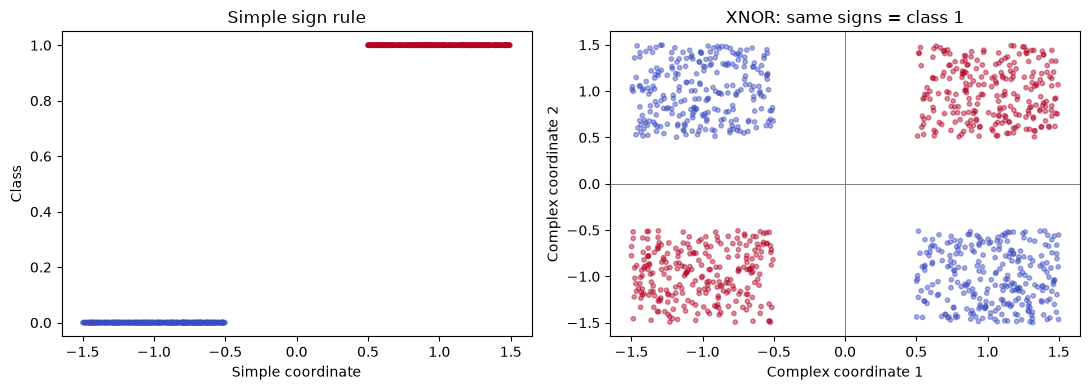

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x[:, 0], y[:, 0], c=y[:, 0], cmap='coolwarm', alpha=0.35, s=10)
axes[0].set(xlabel='Simple coordinate', ylabel='Class', title='Simple sign rule')
axes[1].scatter(x[:, 1], x[:, 2], c=y[:, 0], cmap='coolwarm', alpha=0.45, s=10)
axes[1].axhline(0, color='gray', linewidth=0.7)
axes[1].axvline(0, color='gray', linewidth=0.7)
axes[1].set(xlabel='Complex coordinate 1', ylabel='Complex coordinate 2', title='XNOR: same signs = class 1')
fig.tight_layout()
plt.show()


## Continuous conflict probes

Ordinary samples make both rules agree, so ordinary accuracy cannot identify preference. Conflict probes make their signs disagree while retaining the same magnitude distribution. All four sign configurations occur equally often. The stored complex label is an implied rule label, not ground truth for an out-of-distribution input.

In [6]:
conflict_x, complex_y = splits['conflicts']
simple_y = (conflict_x[:, :1] > 0).float()
assert torch.equal(simple_y, 1 - complex_y)
assert torch.equal((conflict_x[:, 1:2] * conflict_x[:, 2:3] > 0).float(), complex_y)
probe_table = pd.DataFrame(conflict_x.numpy(), columns=['simple', 'complex_1', 'complex_2'])
probe_table['simple_implied_label'] = simple_y.numpy().ravel().astype(int)
probe_table['complex_implied_label'] = complex_y.numpy().ravel().astype(int)
display(probe_table.head(10))
display(probe_table.assign(simple_sign=np.sign(conflict_x[:, 0].numpy()),
                          nuisance_sign=np.sign(conflict_x[:, 1].numpy()))
        .groupby(['simple_sign', 'nuisance_sign']).size().rename('probe_count'))


,simple,complex_1,complex_2,simple_implied_label,complex_implied_label
0,-0.711036,-1.135024,-0.940340,0,1
1,1.134344,-0.654220,0.612536,1,0
2,1.087402,-1.259520,0.735560,1,0
3,-1.063339,0.981386,0.932510,0,1
4,1.006492,0.667544,-1.161206,1,0
5,1.053743,-0.923477,1.260958,1,0
6,1.484439,0.710518,-0.661881,1,0
7,-0.987442,-1.301095,-0.520616,0,1
8,1.204098,0.980211,-1.223456,1,0
9,1.306865,0.706222,-0.551113,1,0


simple_sign  nuisance_sign
-1.0         -1.0             512
              1.0             512
 1.0         -1.0             512
              1.0             512
Name: probe_count, dtype: int64

## Why inverse initialization and compensation still apply

Dividing complex weights by $α$ cancels the scaled input: $(αx)(w/α)=xw$. Starting functions match, but the stored gradient gains a factor $α$. Effective weights are $V=αW$, which introduces a second factor in the effective update: $ΔV=-ηα^2g$. Compensated SGD divides complex gradients by $α^2$ before the optimizer step. This reasoning does not depend on magnitudes being fixed at one.

In [7]:
checks = []
for alpha in [0.1, 0.5, 1, 2, 5, 10]:
    reference, scaled = make_model(42), make_model(42)
    inverse_initialize(scaled, reference, alpha)
    row = initial_checks(reference, scaled, splits['train'], scale_data(splits['train'], alpha), alpha)
    assert max(row.values()) < 1e-5, row
    checks.append({'alpha': alpha, **row})
display(pd.DataFrame(checks))
print('Initial functions and alpha-scaled gradients match to numerical precision.')


,alpha,initial_preactivation_max_error,initial_logit_max_error,initial_gradient_scaling_max_error
0,0.1,2.384186e-07,1.192093e-07,3.492460e-10
1,0.5,0.000000e+00,0.000000e+00,0.000000e+00
2,1.0,0.000000e+00,0.000000e+00,0.000000e+00
3,2.0,0.000000e+00,0.000000e+00,0.000000e+00
4,5.0,4.768372e-07,1.192093e-07,1.490116e-08
5,10.0,4.768372e-07,1.192093e-07,2.980232e-08


Initial functions and alpha-scaled gradients match to numerical precision.


## What remains limited

Held-out coordinates are genuinely distinct, but they come from the same chosen magnitude range. This is not an extrapolation test. Simple and complex groups still have different dimensions. Conflict and sign-flip probes still violate the agreement constraint in the training distribution.